# 1. Импорт и анализ таблиц

Задание 1.1. Импортируйте таблицы и проверьте их на наличие пустых значений

In [48]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scipy.stats as st

In [49]:
df_data = pd.read_excel("ab-test-data.xlsx", sheet_name = "Данные")
df_clients = pd.read_excel("ab-test-data.xlsx", sheet_name = "Clients")
df_regions = pd.read_excel("ab-test-data.xlsx", sheet_name = "Region_dict")

Задание 1.2-1.3. Изучите все три таблицы и проверьте их на наличие пустых значений. Исключите из таблиц все строки, в которых есть нулловые значения. 

Если посмотреть на данные глазами в excel файле, то во вкладке data видно, что строки с неполными данными правктически всегда теряют как минимум dtime_pay, и одновременно с ним могут быть потеряны и amt_payment, и id_client. Мы могли бы при отсутствии только amt_payment забить эти пустые строки значением среднего или медианного платежа, но дату платежа и тем более id клиента мы так просто не восстановим. Поэтмоу сначала посмотрим на количество пустых строк, и если оно небольшое, а именно < 10%, то просто удалим эти строки.

In [50]:
# оценим, сколько пустых строк
df_data.isnull().sum()

# 2429 строк - это 6,4%, поэтому смело их удалим. И посмотрим, как изменилась статистика.



id_order          0
id_client       588
amt_payment    2144
dtime_pay      2429
dtype: int64

In [51]:
df_data

,id_order,id_client,amt_payment,dtime_pay
0,100238,194569.0,5373.0,2022-07-17 21:48:15.896
1,100242,191056.0,4151.0,2022-07-07 03:09:39.699
2,100249,200049.0,5688.0,2022-07-29 13:25:59.976
3,100258,206161.0,4330.0,2022-08-15 22:55:02.538
4,100267,190945.0,5488.0,2022-07-05 19:46:47.174
...,...,...,...,...
37984,297586,NaN,NaN,NaT
37985,297593,179230.0,5755.0,2022-06-05 19:40:07.096
37986,297595,192530.0,4448.0,2022-07-09 18:43:02.810
37987,297601,183888.0,1746.0,2022-06-20 06:24:42.155


In [52]:
df_data.describe()

,id_order,id_client,amt_payment,dtime_pay
count,37989.000000,37401.000000,35845.000000,35560
mean,197751.747085,194078.460710,3542.546464,2022-07-15 06:05:14.001493248
min,100238.000000,178561.000000,498.000000,2022-06-04 02:51:21.878000
25%,148504.000000,186334.000000,2582.000000,2022-06-25 22:28:13.217499904
50%,197658.000000,194069.000000,3470.000000,2022-07-15 04:35:15.531500032
75%,246441.000000,201831.000000,4389.000000,2022-08-03 14:11:16.191000064
max,297607.000000,209634.000000,7633.000000,2022-08-29 10:21:05.025000
std,56733.647764,8972.581221,1426.815593,NaN


In [53]:
df_data.dtypes

id_order                int64
id_client             float64
amt_payment           float64
dtime_pay      datetime64[ns]
dtype: object

Задание. Исключите из таблиц все строки, в которых есть нулловые значения

In [54]:
df_data_clean = df_data.dropna()

df_data_clean

,id_order,id_client,amt_payment,dtime_pay
0,100238,194569.0,5373.0,2022-07-17 21:48:15.896
1,100242,191056.0,4151.0,2022-07-07 03:09:39.699
2,100249,200049.0,5688.0,2022-07-29 13:25:59.976
3,100258,206161.0,4330.0,2022-08-15 22:55:02.538
4,100267,190945.0,5488.0,2022-07-05 19:46:47.174
...,...,...,...,...
37983,297572,195257.0,2191.0,2022-07-16 16:11:15.874
37985,297593,179230.0,5755.0,2022-06-05 19:40:07.096
37986,297595,192530.0,4448.0,2022-07-09 18:43:02.810
37987,297601,183888.0,1746.0,2022-06-20 06:24:42.155


Было удалено 2 439 строк, что на 10 строк превышает количество пустых dtimepay. На статистику эти строки практически никак не повлияли.

In [55]:
df_data_clean.describe()

,id_order,id_client,amt_payment,dtime_pay
count,35560.000000,35560.000000,35560.000000,35560
mean,197768.890804,194089.864511,3542.339623,2022-07-15 06:05:14.001493248
min,100238.000000,178561.000000,498.000000,2022-06-04 02:51:21.878000
25%,148567.000000,186352.750000,2581.000000,2022-06-25 22:28:13.217499904
50%,197639.500000,194074.500000,3470.000000,2022-07-15 04:35:15.531500032
75%,246340.500000,201863.250000,4390.000000,2022-08-03 14:11:16.191000064
max,297607.000000,209634.000000,7633.000000,2022-08-29 10:21:05.025000
std,56689.034409,8973.216267,1427.383578,NaN


Видим, что столбец id_client имеют тип данных float. Переведем его в формат int для последующего удобства.

In [56]:
df_data_clean = df_data_clean.copy()
df_data_clean['id_client'] = df_data_clean['id_client'].astype(int)

df_data_clean.dtypes

id_order                int64
id_client               int64
amt_payment           float64
dtime_pay      datetime64[ns]
dtype: object

In [57]:
df_data_clean

,id_order,id_client,amt_payment,dtime_pay
0,100238,194569,5373.0,2022-07-17 21:48:15.896
1,100242,191056,4151.0,2022-07-07 03:09:39.699
2,100249,200049,5688.0,2022-07-29 13:25:59.976
3,100258,206161,4330.0,2022-08-15 22:55:02.538
4,100267,190945,5488.0,2022-07-05 19:46:47.174
...,...,...,...,...
37983,297572,195257,2191.0,2022-07-16 16:11:15.874
37985,297593,179230,5755.0,2022-06-05 19:40:07.096
37986,297595,192530,4448.0,2022-07-09 18:43:02.810
37987,297601,183888,1746.0,2022-06-20 06:24:42.155


Теперь все выглядит значительно лучше. Осталось проверить наличие дубликатов.

In [58]:
duplicates_only = df_data_clean[df_data_clean.duplicated()]
print(duplicates_only)

Empty DataFrame
Columns: [id_order, id_client, amt_payment, dtime_pay]
Index: []


Дубликатов не найдено. Считаем данные с листа data очищены и готовыми к работе. Лист region_dict не имеет пропусков. Осталось почистить лист Clients.

In [59]:
df_clients

,id_client,dtime_ad,nflag_test,id_trading_point
0,180844,2022-06-08 18:38:41.414,0,212
1,193942,NaT,0,13
2,226069,2022-07-11 16:28:38.511,1,54
3,183981,2022-06-16 12:23:59.289,1,991
4,322530,2022-07-08 08:56:08.714,0,1015
...,...,...,...,...
55600,193038,2022-07-09 00:31:25.196,0,1015
55601,244069,2022-08-08 00:12:31.319,1,991
55602,189084,2022-06-29 04:34:42.610,1,439
55603,182758,2022-06-13 11:28:37.856,1,573


In [60]:
df_clients.isnull().sum()

id_client             0
dtime_ad            249
nflag_test            0
id_trading_point      0
dtype: int64

In [61]:
df_clients_clean = df_clients.dropna()

df_clients_clean

,id_client,dtime_ad,nflag_test,id_trading_point
0,180844,2022-06-08 18:38:41.414,0,212
2,226069,2022-07-11 16:28:38.511,1,54
3,183981,2022-06-16 12:23:59.289,1,991
4,322530,2022-07-08 08:56:08.714,0,1015
5,254313,2022-06-19 22:18:01.770,1,453
...,...,...,...,...
55600,193038,2022-07-09 00:31:25.196,0,1015
55601,244069,2022-08-08 00:12:31.319,1,991
55602,189084,2022-06-29 04:34:42.610,1,439
55603,182758,2022-06-13 11:28:37.856,1,573


In [62]:
df_clients_clean.dtypes

id_client                    int64
dtime_ad            datetime64[ns]
nflag_test                   int64
id_trading_point             int64
dtype: object

In [63]:
# посмотрим, есть ли задвоения в данных

duplicates_only = df_clients_clean[df_clients_clean.duplicated()]
print(duplicates_only)

#дубликатов не найдено

Empty DataFrame
Columns: [id_client, dtime_ad, nflag_test, id_trading_point]
Index: []


В итоге получили три датафрейма:
1) df_data_clean
2) df_clients_clean
3) df_region_dict

Задание 1.4. Исследуйте количество торговых точек в каждом городе — постройте группировку по количеству в каждом городе и визуализируйте с помощью столбчатой диаграммы.

In [64]:
df_regions

,id_trading_point,city
0,1,Петрозаводск
1,2,Дмитров
2,4,Чехов
3,7,Ростов Великий
4,11,Владимир
...,...,...
61,3987,Москва
62,6543,Москва
63,8543,Москва
64,9121,Москва


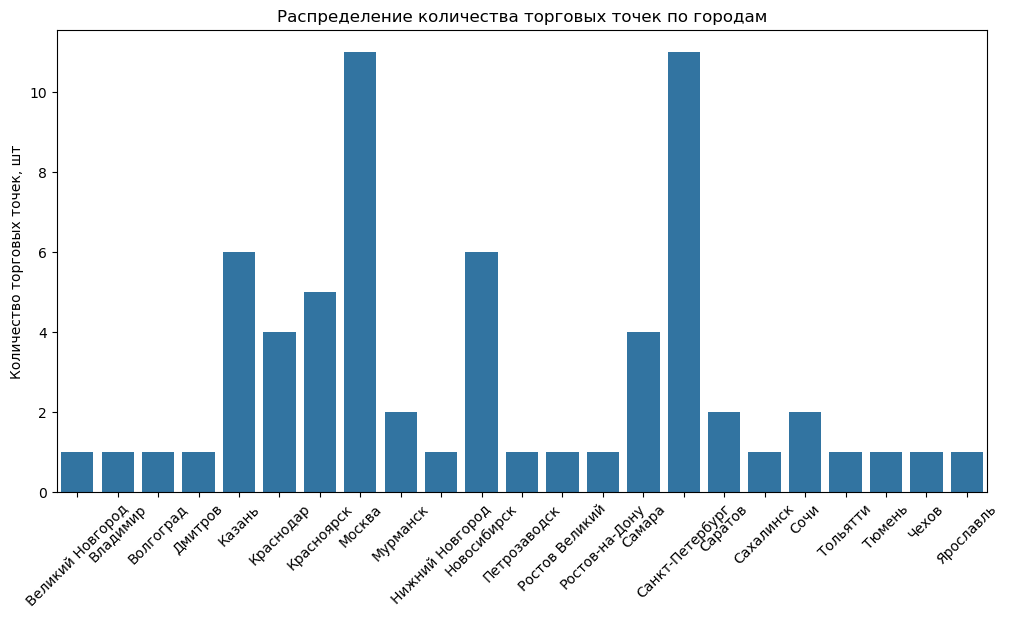

In [65]:
df_trading_points = df_regions.groupby("city").agg(cnt = ('id_trading_point', 'count'))


plt.figure(figsize = (12, 6)) 
sns.barplot(data = df_trading_points, x = "city", y = "cnt")
plt.ylabel('Количество торговых точек, шт')
plt.xlabel('')
plt.title('Распределение количества торговых точек по городам')
plt.xticks(rotation=45)
plt.show()


Выводы. Наибольшее количество торговых точек (>10) наблюдается в двух столицах, дальше от 4 до 6 точек располагается в крупных городах, таких как Казань, Краснодар, Красноярск, Нижний Новгород и Самара. Правда, почему-то выбиваются Волгоград и Новосибирск, которые тоже города-миллионники, но торговых точек там представлено всего по одной.

# 2. Объединение таблиц

Задание 2.1. У одного клиента может быть несколько платежей. Постройте агрегацию таблицы с платежами, где вычислите сумму платежей на каждого клиента

In [66]:
df_data_clean.dtypes

id_order                int64
id_client               int64
amt_payment           float64
dtime_pay      datetime64[ns]
dtype: object

In [67]:
df_data_agg = df_data_clean.groupby('id_client').agg(all_payments = ('amt_payment', 'sum'))

df_data_agg

,all_payments
id_client,
178561,3052.0
178562,2439.0
178563,768.0
178565,958.0
178566,5474.0
...,...
209630,6927.0
209631,2090.0
209632,2775.0


Задание 2.2. Соедините (по клиенту) сгруппированную таблицу с платежами с клиентской таблицей. Убедитесь, что в таблице остались все клиенты из клиентской таблицы.

In [68]:
df_client_pay_merged = pd.merge(df_data_agg, df_clients_clean, how = 'right', on = 'id_client')

if df_clients_clean['id_client'].nunique() == df_client_pay_merged['id_client'].nunique():
    print('Все клиенты из клиентской таблицы остались в новой таблице')
else:
    print('НЕ ВСЕ клиенты из клиентской таблицы попали в новую таблицу')


Все клиенты из клиентской таблицы остались в новой таблице


Задание 2.3. Заполните нулями суммы покупок тех клиентов, которые их не совершали.

In [69]:
df_client_pay_merged['all_payments'] = df_client_pay_merged['all_payments'].fillna(0)

df_client_pay_merged

,id_client,all_payments,dtime_ad,nflag_test,id_trading_point
0,180844,5349.0,2022-06-08 18:38:41.414,0,212
1,226069,0.0,2022-07-11 16:28:38.511,1,54
2,183981,6322.0,2022-06-16 12:23:59.289,1,991
3,322530,0.0,2022-07-08 08:56:08.714,0,1015
4,254313,0.0,2022-06-19 22:18:01.770,1,453
...,...,...,...,...,...
55351,193038,5846.0,2022-07-09 00:31:25.196,0,1015
55352,244069,0.0,2022-08-08 00:12:31.319,1,991
55353,189084,7146.0,2022-06-29 04:34:42.610,1,439
55354,182758,13720.0,2022-06-13 11:28:37.856,1,573


Задание 2.4. С помощью словаря регионов подтяните к каждой торговой точке город, в котором она находится.

In [70]:
df_client_pay_merged = df_client_pay_merged.merge(
    df_regions[['id_trading_point', 'city']],
    on = 'id_trading_point',
    how = 'left'
)

df_client_pay_merged

,id_client,all_payments,dtime_ad,nflag_test,id_trading_point,city
0,180844,5349.0,2022-06-08 18:38:41.414,0,212,Красноярск
1,226069,0.0,2022-07-11 16:28:38.511,1,54,Мурманск
2,183981,6322.0,2022-06-16 12:23:59.289,1,991,Казань
3,322530,0.0,2022-07-08 08:56:08.714,0,1015,Краснодар
4,254313,0.0,2022-06-19 22:18:01.770,1,453,Санкт-Петербург
...,...,...,...,...,...,...
55351,193038,5846.0,2022-07-09 00:31:25.196,0,1015,Краснодар
55352,244069,0.0,2022-08-08 00:12:31.319,1,991,Казань
55353,189084,7146.0,2022-06-29 04:34:42.610,1,439,Казань
55354,182758,13720.0,2022-06-13 11:28:37.856,1,573,Санкт-Петербург


Задание 2.5. Создайте поле флаг платежа, который принимает значения 0 или 1 в зависимости от того, заплатил клиент или нет.

In [71]:
df_client_pay_merged['payment_flag'] = np.where(df_client_pay_merged['all_payments'] > 0, 1, 0)

df_client_pay_merged

,id_client,all_payments,dtime_ad,nflag_test,id_trading_point,city,payment_flag
0,180844,5349.0,2022-06-08 18:38:41.414,0,212,Красноярск,1
1,226069,0.0,2022-07-11 16:28:38.511,1,54,Мурманск,0
2,183981,6322.0,2022-06-16 12:23:59.289,1,991,Казань,1
3,322530,0.0,2022-07-08 08:56:08.714,0,1015,Краснодар,0
4,254313,0.0,2022-06-19 22:18:01.770,1,453,Санкт-Петербург,0
...,...,...,...,...,...,...,...
55351,193038,5846.0,2022-07-09 00:31:25.196,0,1015,Краснодар,1
55352,244069,0.0,2022-08-08 00:12:31.319,1,991,Казань,0
55353,189084,7146.0,2022-06-29 04:34:42.610,1,439,Казань,1
55354,182758,13720.0,2022-06-13 11:28:37.856,1,573,Санкт-Петербург,1


# 3. Автоматизация статистических вычислений

Задание 3.1. Создайте функцию test_calc, которая будет вычислять значение t-критерия (критерия Стьюдента) и p_value для сравнения средних и с помощью функции print выводить сообщение о том, существует ли разница между средними (на основании p_value).

In [72]:
def test_calc(r1, r2 , alpha = 0.05):
    t_stat, p_value = st.ttest_ind(r1, r2)
    print(f'Согласно проведенному T-тесту для средних значений двух независимых выборок\n'
          f'p-value равен {p_value}, а значение t-критерия равно {t_stat}')
    if p_value > alpha:
        print('Статистически значимых различий между двумя выборками не обнаружено')
    else:
        print('Значения двух выборок имеют статистически значимые различия')
    return t_stat, p_value


Задание 3.3. Создайте функцию mann_whitney_func, которая будет рассчитывать значение критерия Манна Уитни и p_value для сравнения распределений и с помощью функции print выводить сообщение о том, существует ли разница между средними (на основании p_value).

In [73]:
def mann_whitney_func(r1, r2 , alpha = 0.05):
    statistic, p_value = st.mannwhitneyu(r1, r2)
    print(f'Согласно проведенному непараметрическому тесту Манна-Уитни для средних значений двух независимых выборок\n'
          f'p-value равен {p_value}, а значение U-статистики для первой выборки равно {statistic}')
    if p_value > alpha:
        print('Статистически значимых различий между двумя выборками не обнаружено')
    else:
        print('Значения двух выборок имеют статистически значимые различия')

# 4. Чистка неверно заполненных точек

Задание 4.1. Создайте пустой список. Запустите цикл по всем торговым точкам и добавьте к этому списку все торговые точки, в которых в тестовой или в контрольной группе не было заплачено ни одного рубля ни одним клиентом.

In [74]:
#короткое решение
tmp_list = []
sum_pay = 0

for i in df_client_pay_merged['id_trading_point'].unique():
    sum_pay_control = df_client_pay_merged[(df_client_pay_merged['nflag_test'] == 0) & (df_client_pay_merged['id_trading_point'] == i)]['all_payments'].sum()
    sum_pay_test = df_client_pay_merged[(df_client_pay_merged['nflag_test'] == 1) & (df_client_pay_merged['id_trading_point'] == i)]['all_payments'].sum()
    if sum_pay_control == 0 or sum_pay_test == 0:
        tmp_list.append(int(i))

print(tmp_list)

[1015, 866, 1099, 739, 46, 228, 26, 603, 810, 800, 7, 23, 4, 1, 13]


In [75]:
#более подробная запись

tmp_list = []

for i in df_client_pay_merged['id_trading_point'].unique():
    df_tr_point = df_client_pay_merged[df_client_pay_merged['id_trading_point'] == i]
    df_tr_point_control = df_tr_point[df_tr_point['nflag_test'] == 0]
    df_tr_point_test = df_tr_point[df_tr_point['nflag_test'] == 1]
    sum_control = df_tr_point_control['all_payments'].sum()
    sum_test = df_tr_point_test['all_payments'].sum()
    if sum_control == 0 or sum_test == 0:
        tmp_list.append(int(i))

print(tmp_list)

[1015, 866, 1099, 739, 46, 228, 26, 603, 810, 800, 7, 23, 4, 1, 13]


Задание 4.2. Создайте еще один пустой список. Запустите цикл по всем торговым точкам и добавьте к этому списку все торговые точки, в которых пустует или контрольная, или тестовая группа.

In [76]:
tmp_list_cnt = []

for i in df_client_pay_merged['id_trading_point'].unique():
    df_tr_point_cnt = df_client_pay_merged[df_client_pay_merged['id_trading_point'] == i]
    df_tr_point_control_cnt = df_tr_point_cnt[df_tr_point_cnt['nflag_test'] == 0]
    df_tr_point_test_cnt = df_tr_point_cnt[df_tr_point_cnt['nflag_test'] == 1]
    cnt_control = len(df_tr_point_control_cnt)
    cnt_test = len(df_tr_point_test_cnt)
    if cnt_control == 0 or cnt_test == 0:
        tmp_list_cnt.append(int(i))

print(tmp_list_cnt)

[1015, 866, 1099, 739, 228, 603, 810, 800]


# 5. Расчет общих результатов A/B-теста

Задание 5.1. Отбросьте все торговые точки, которые были вами обнаружены в пункте 4. Пояснение: если сумма платежей или количество наблюдений в одной из групп будет равно 0, то мы не сможем сравнить платежи в тестовой и контрольной группах, или такое сравнение будет неверным.

In [77]:

final_list = set(tmp_list_cnt + tmp_list)

df_final = df_client_pay_merged[~ df_client_pay_merged['id_trading_point'].isin(final_list)]

df_final

,id_client,all_payments,dtime_ad,nflag_test,id_trading_point,city,payment_flag
0,180844,5349.0,2022-06-08 18:38:41.414,0,212,Красноярск,1
1,226069,0.0,2022-07-11 16:28:38.511,1,54,Мурманск,0
2,183981,6322.0,2022-06-16 12:23:59.289,1,991,Казань,1
4,254313,0.0,2022-06-19 22:18:01.770,1,453,Санкт-Петербург,0
5,195818,4021.0,2022-07-16 01:30:59.088,1,2652,Москва,1
...,...,...,...,...,...,...,...
55350,188702,1323.0,2022-06-28 06:16:25.664,0,453,Санкт-Петербург,1
55352,244069,0.0,2022-08-08 00:12:31.319,1,991,Казань,0
55353,189084,7146.0,2022-06-29 04:34:42.610,1,439,Казань,1
55354,182758,13720.0,2022-06-13 11:28:37.856,1,573,Санкт-Петербург,1


Задание 5.2. Изобразите гистограмму платежей, на которой различными цветами изображены группы «тест» и «контроль».

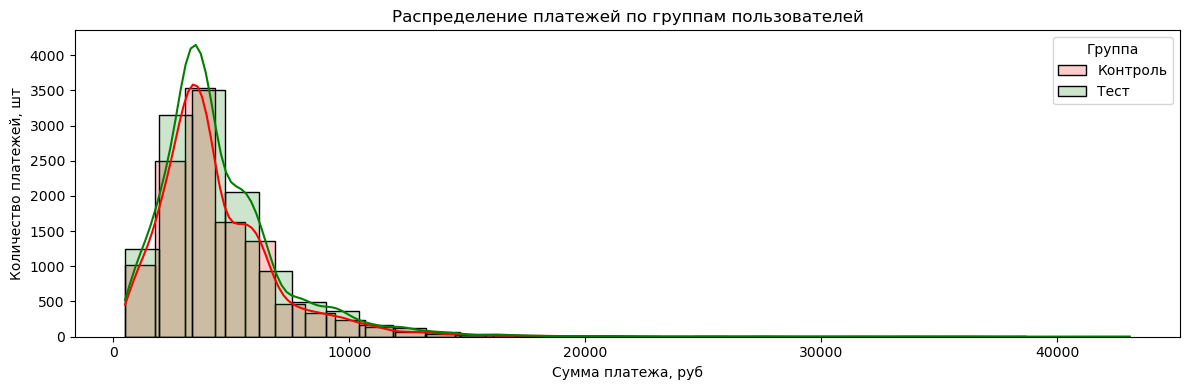

In [78]:
data_test = df_final[(df_final['nflag_test'] == 1) & (df_final['all_payments'] > 0)]
data_control = df_final[(df_final['nflag_test'] == 0) & (df_final['all_payments'] > 0)]

fig, ax = plt.subplots(figsize = (12, 4))

sns.histplot(data = data_control, x = 'all_payments', bins=30, color='red', alpha = 0.2, label = 'Контроль', kde = True)
sns.histplot(data = data_test, x = 'all_payments', bins=30, color='green', alpha = 0.2, label = 'Тест', kde = True)

ax.set_title('Распределение платежей по группам пользователей')
ax.set_xlabel('Сумма платежа, руб')
ax.set_ylabel('Количество платежей, шт')
ax.legend(title = 'Группа')
plt.tight_layout()
plt.show()


Задание 5.3. Примените функцию test_calc и сделайте вывод (сравниваем средние платежи)

In [79]:
test_calc(
    df_final[df_final['nflag_test'] == 0]['all_payments'], 
    df_final[df_final['nflag_test'] == 1]['all_payments']
)

Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 3.3214645838934018e-21, а значение t-критерия равно -9.456798235171377
Значения двух выборок имеют статистически значимые различия


(np.float64(-9.456798235171377), np.float64(3.3214645838934018e-21))

Вывод: Согласно проведённому T-тесту для средних значений двух независимых выборок, p-value равен 3*10^-21, а значение t-критерия равно -9,45. Поскольку p-value значительно меньше уровня значимости 0,05, то значения средних платежей двух выборок имеют статистически значимые различия.

Задание 5.4. Примените функцию test_calc и сделайте вывод (сравниваем конверсию в платеж, то есть r1 и r2 — это ряды нулей и единиц, в зависимости от того, оплатил ли что-то клиент или нет).

In [80]:
test_calc(
    df_final[df_final['nflag_test'] == 0]['payment_flag'], 
    df_final[df_final['nflag_test'] == 1]['payment_flag']
)

Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 1.7338073027564523e-20, а значение t-критерия равно -9.282032730948323
Значения двух выборок имеют статистически значимые различия


(np.float64(-9.282032730948323), np.float64(1.7338073027564523e-20))

Вывод: Согласно проведённому T-тесту для средних значений двух независимых выборок, p-value равен 1,7*10^-20, а значение t-критерия равно -9,28. Поскольку p-value значительно меньше уровня значимости 0,05, то значения конверсии в платеж двух выборок имеют статистически значимые различия.

Задание 5.5 Примените функцию mann_whitney_func и сделайте вывод.

In [81]:
mann_whitney_func(
    df_final[df_final['nflag_test'] == 0]['all_payments'], 
    df_final[df_final['nflag_test'] == 1]['all_payments']
)

Согласно проведенному непараметрическому тесту Манна-Уитни для средних значений двух независимых выборок
p-value равен 3.008345273971901e-24, а значение U-статистики для первой выборки равно 243344369.0
Значения двух выборок имеют статистически значимые различия


Вывод: тест Манна-Уитни показал те же статистически значимые различия в средних платежах двух выборок, что и Т-тест Стьюдента.

# 6. Сегментация результатов A/B-теста

6.1. Повторите аналитику из пункта 5 в отношении Москвы. Сделайте выводы.

In [82]:
test_calc(
    df_final[(df_final['nflag_test'] == 0) & (df_final['city'] == 'Москва')]['all_payments'],
    df_final[(df_final['nflag_test'] == 1) & (df_final['city'] == 'Москва')]['all_payments']
)

Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 1.757549439555765e-14, а значение t-критерия равно -7.676511027843395
Значения двух выборок имеют статистически значимые различия


(np.float64(-7.676511027843395), np.float64(1.757549439555765e-14))

Вывод: Поскольку p-value значительно меньше уровня значимости 0,05, то значения средних платежей двух групп пользователей в Москве имеют статистически значимые различия.

In [83]:
test_calc(
    df_final[(df_final['nflag_test'] == 0) & (df_final['city'] == 'Москва')]['payment_flag'], 
    df_final[(df_final['nflag_test'] == 1) & (df_final['city'] == 'Москва')]['payment_flag']
)

Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 6.194689260032594e-10, а значение t-критерия равно -6.190312288026295
Значения двух выборок имеют статистически значимые различия


(np.float64(-6.190312288026295), np.float64(6.194689260032594e-10))

Вывод: Поскольку p-value значительно меньше уровня значимости 0,05, то значения конверсии в платеж двух групп пользователей в Москве имеют статистически значимые различия.

In [84]:
mann_whitney_func(
    df_final[(df_final['nflag_test'] == 0) & (df_final['city'] == 'Москва')]['all_payments'], 
    df_final[(df_final['nflag_test'] == 1) & (df_final['city'] == 'Москва')]['all_payments']
)

Согласно проведенному непараметрическому тесту Манна-Уитни для средних значений двух независимых выборок
p-value равен 7.010591402203484e-16, а значение U-статистики для первой выборки равно 17582441.5
Значения двух выборок имеют статистически значимые различия


Вывод: тест Манна-Уитни показал те же статистически значимые различия в средних платежах двух выборок, что и Т-тест Стьюдента.

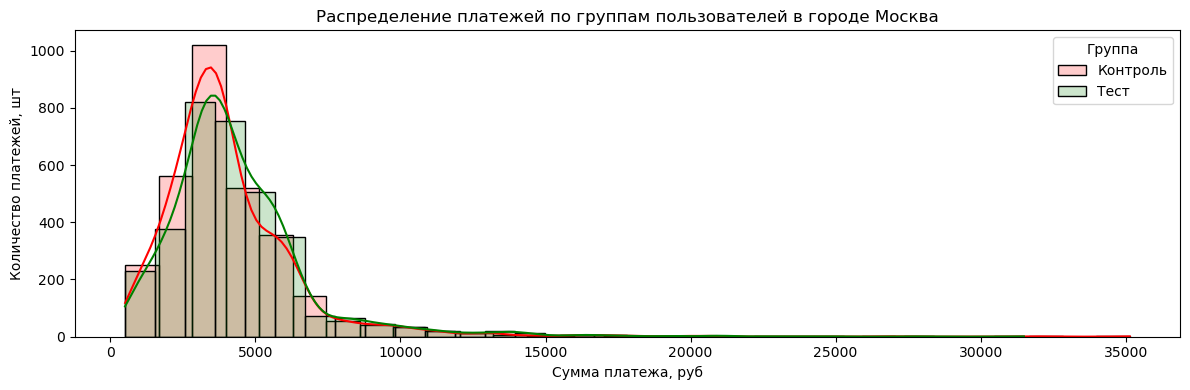

In [85]:
df_final_msk = df_final[df_final['city'] == 'Москва']

data_test_msk = df_final_msk[(df_final_msk['nflag_test'] == 1) & (df_final_msk['all_payments'] > 0)]
data_control_msk = df_final_msk[(df_final_msk['nflag_test'] == 0) & (df_final_msk['all_payments'] > 0)]

fig, ax = plt.subplots(figsize = (12, 4))

sns.histplot(data = data_control_msk, x = 'all_payments', bins=30, color='red', alpha = 0.2, label = 'Контроль', kde = True)
sns.histplot(data = data_test_msk, x = 'all_payments', bins=30, color='green', alpha = 0.2, label = 'Тест', kde = True)

ax.set_title('Распределение платежей по группам пользователей в городе Москва')
ax.set_xlabel('Сумма платежа, руб')
ax.set_ylabel('Количество платежей, шт')
ax.legend(title = 'Группа')
plt.tight_layout()
plt.show()

6.2. Повторите аналитику из пункта 5 в отношении Санкт-Петербурга. Сделайте выводы.

In [86]:
test_calc(
    df_final[(df_final['nflag_test'] == 0) & (df_final['city'] == 'Санкт-Петербург')]['all_payments'],
    df_final[(df_final['nflag_test'] == 1) & (df_final['city'] == 'Санкт-Петербург')]['all_payments']
)

Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 2.3198088937974163e-18, а значение t-критерия равно -8.759635784179547
Значения двух выборок имеют статистически значимые различия


(np.float64(-8.759635784179547), np.float64(2.3198088937974163e-18))

Вывод: Поскольку p-value значительно меньше уровня значимости 0,05, то значения средних платежей двух групп пользователей в Санкт-Петербурге имеют статистически значимые различия.

In [87]:
test_calc(
    df_final[(df_final['nflag_test'] == 0) & (df_final['city'] == 'Санкт-Петербург')]['payment_flag'], 
    df_final[(df_final['nflag_test'] == 1) & (df_final['city'] == 'Санкт-Петербург')]['payment_flag']
)

Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 1.065825659919673e-20, а значение t-критерия равно -9.352468686561785
Значения двух выборок имеют статистически значимые различия


(np.float64(-9.352468686561785), np.float64(1.065825659919673e-20))

Вывод: Поскольку p-value значительно меньше уровня значимости 0,05, то значения конверсии в платеж двух групп пользователей в Санкт-Петербурге имеют статистически значимые различия.

In [88]:
mann_whitney_func(
    df_final[(df_final['nflag_test'] == 0) & (df_final['city'] == 'Санкт-Петербург')]['all_payments'], 
    df_final[(df_final['nflag_test'] == 1) & (df_final['city'] == 'Санкт-Петербург')]['all_payments']
)

Согласно проведенному непараметрическому тесту Манна-Уитни для средних значений двух независимых выборок
p-value равен 2.0392184217953754e-20, а значение U-статистики для первой выборки равно 8809444.5
Значения двух выборок имеют статистически значимые различия


Вывод: тест Манна-Уитни показал те же статистически значимые различия в средних платежах двух выборок, что и Т-тест Стьюдента.

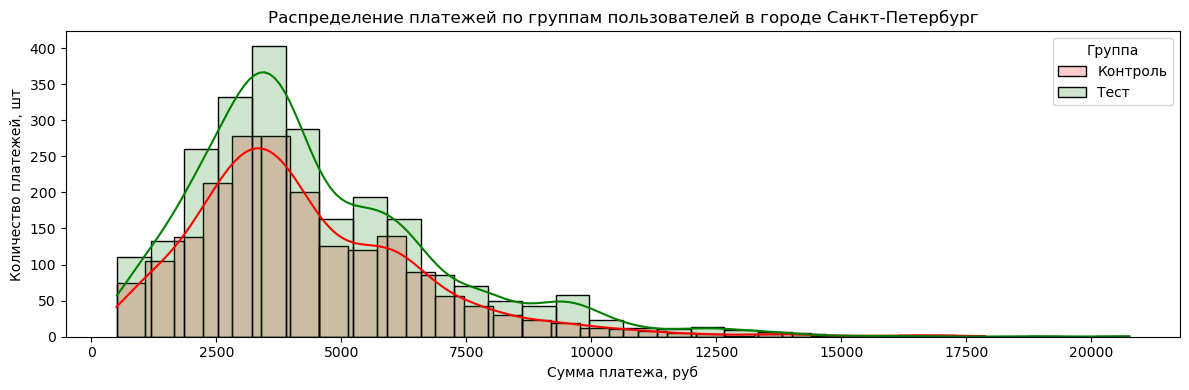

In [89]:
df_final_spb = df_final[df_final['city'] == 'Санкт-Петербург']

data_test_spb = df_final_spb[(df_final_spb['nflag_test'] == 1) & (df_final_spb['all_payments'] > 0)]
data_control_spb = df_final_spb[(df_final_spb['nflag_test'] == 0) & (df_final_spb['all_payments'] > 0)]

fig, ax = plt.subplots(figsize = (12, 4))

sns.histplot(data = data_control_spb, x = 'all_payments', bins=30, color='red', alpha = 0.2, label = 'Контроль', kde = True)
sns.histplot(data = data_test_spb, x = 'all_payments', bins=30, color='green', alpha = 0.2, label = 'Тест', kde = True)

ax.set_title('Распределение платежей по группам пользователей в городе Санкт-Петербург')
ax.set_xlabel('Сумма платежа, руб')
ax.set_ylabel('Количество платежей, шт')
ax.legend(title = 'Группа')
plt.tight_layout()
plt.show()

6.3 Запустите цикл по оставшимся городам. Проведите такой же анализ.

Красноярск 



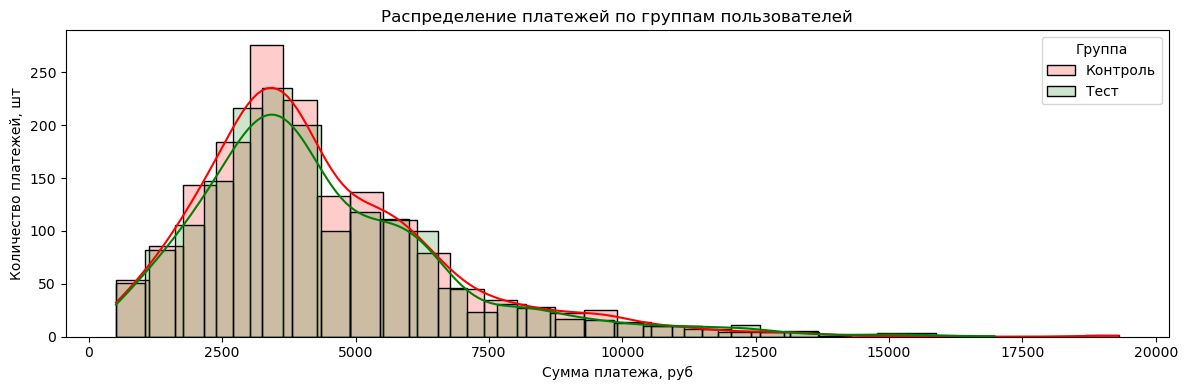

Т-тест Стюдента для средних платежей:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.9044823881233125, а значение t-критерия равно -0.12000608689929208
Статистически значимых различий между двумя выборками не обнаружено


Т-тест Стюдента для средних значений конверсии в платеж:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.7805336501430107, а значение t-критерия равно 0.27863631219717744
Статистически значимых различий между двумя выборками не обнаружено


Тест Манна-Уитни для средних платежей:
Согласно проведенному непараметрическому тесту Манна-Уитни для средних значений двух независимых выборок
p-value равен 0.8770469886251647, а значение U-статистики для первой выборки равно 4413418.0
Статистически значимых различий между двумя выборками не обнаружено


Мурманск 



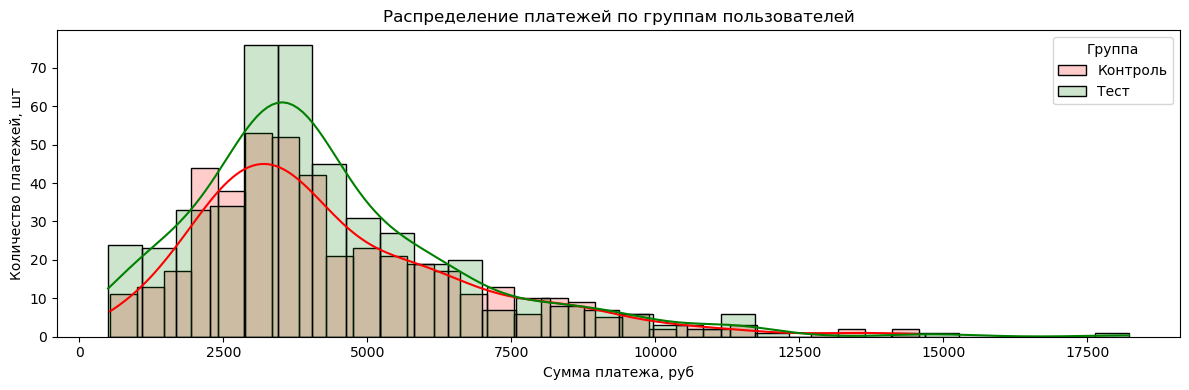

Т-тест Стюдента для средних платежей:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.9449762446327565, а значение t-критерия равно -0.06902498862889384
Статистически значимых различий между двумя выборками не обнаружено


Т-тест Стюдента для средних значений конверсии в платеж:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.3976422846466432, а значение t-критерия равно -0.8460108060373052
Статистически значимых различий между двумя выборками не обнаружено


Тест Манна-Уитни для средних платежей:
Согласно проведенному непараметрическому тесту Манна-Уитни для средних значений двух независимых выборок
p-value равен 0.5434251528583327, а значение U-статистики для первой выборки равно 554067.5
Статистически значимых различий между двумя выборками не обнаружено


Казань 



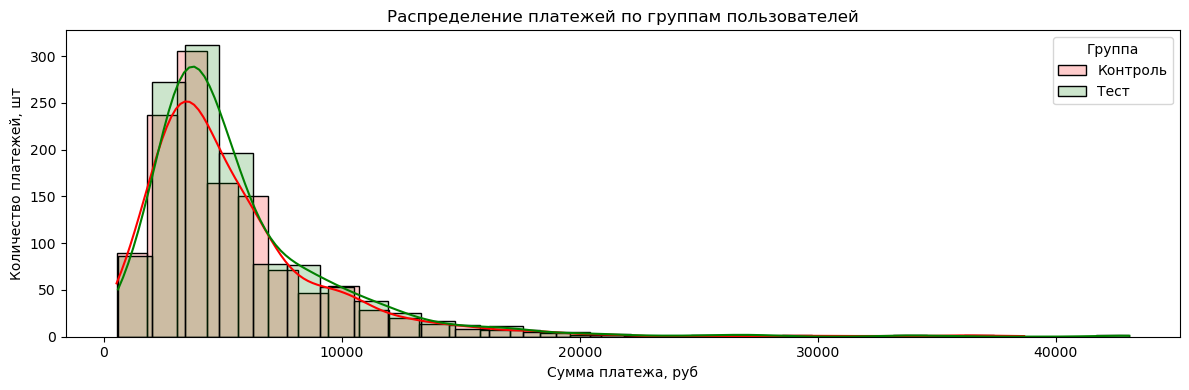

Т-тест Стюдента для средних платежей:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.286688049247618, а значение t-критерия равно -1.0655273408818378
Статистически значимых различий между двумя выборками не обнаружено


Т-тест Стюдента для средних значений конверсии в платеж:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.784829789025573, а значение t-критерия равно -0.27304492857426443
Статистически значимых различий между двумя выборками не обнаружено


Тест Манна-Уитни для средних платежей:
Согласно проведенному непараметрическому тесту Манна-Уитни для средних значений двух независимых выборок
p-value равен 0.37726004167062477, а значение U-статистики для первой выборки равно 3178575.0
Статистически значимых различий между двумя выборками не обнаружено


Саратов 



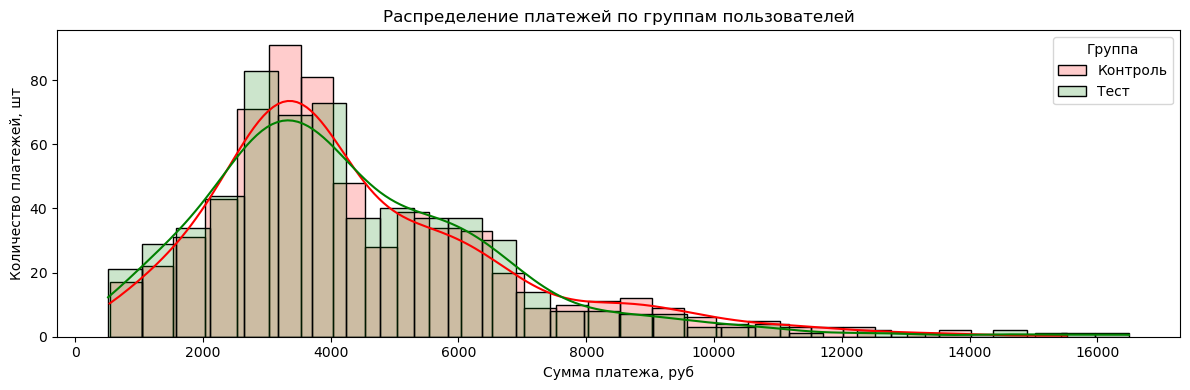

Т-тест Стюдента для средних платежей:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.9162512798549167, а значение t-критерия равно 0.10516947629572568
Статистически значимых различий между двумя выборками не обнаружено


Т-тест Стюдента для средних значений конверсии в платеж:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.5152558091282406, а значение t-критерия равно -0.6507850002388366
Статистически значимых различий между двумя выборками не обнаружено


Тест Манна-Уитни для средних платежей:
Согласно проведенному непараметрическому тесту Манна-Уитни для средних значений двух независимых выборок
p-value равен 0.7833257779753139, а значение U-статистики для первой выборки равно 557976.5
Статистически значимых различий между двумя выборками не обнаружено


Тольятти 



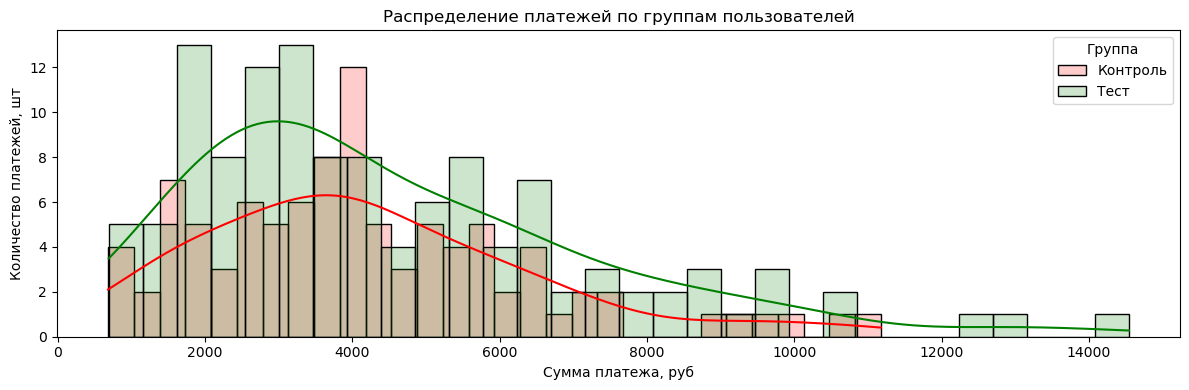

Т-тест Стюдента для средних платежей:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.1333273246710206, а значение t-критерия равно -1.5045563456740754
Статистически значимых различий между двумя выборками не обнаружено


Т-тест Стюдента для средних значений конверсии в платеж:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.23675311799785542, а значение t-критерия равно -1.185144360467606
Статистически значимых различий между двумя выборками не обнаружено


Тест Манна-Уитни для средних платежей:
Согласно проведенному непараметрическому тесту Манна-Уитни для средних значений двух независимых выборок
p-value равен 0.22134177144014489, а значение U-статистики для первой выборки равно 14709.5
Статистически значимых различий между двумя выборками не обнаружено


Тюмень 



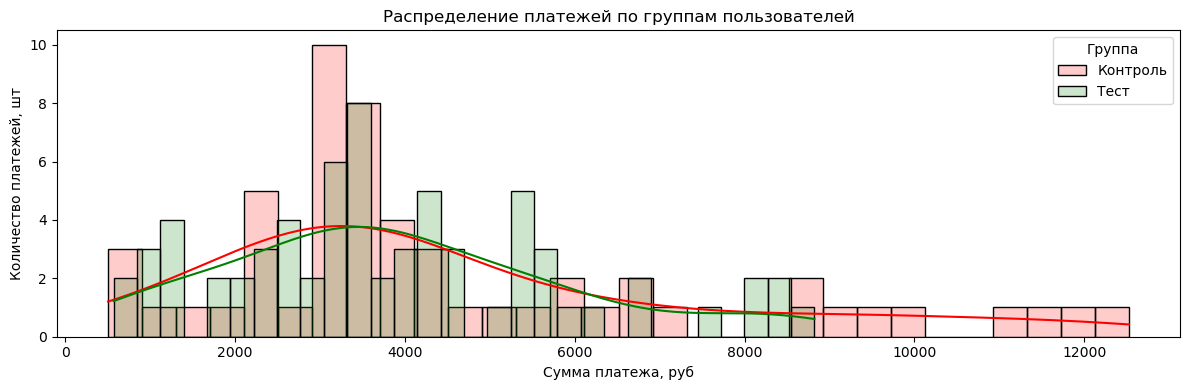

Т-тест Стюдента для средних платежей:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.3550227648604757, а значение t-критерия равно -0.9264590634677944
Статистически значимых различий между двумя выборками не обнаружено


Т-тест Стюдента для средних значений конверсии в платеж:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.01451825932213329, а значение t-критерия равно -2.4598250966325907
Значения двух выборок имеют статистически значимые различия


Тест Манна-Уитни для средних платежей:
Согласно проведенному непараметрическому тесту Манна-Уитни для средних значений двух независимых выборок
p-value равен 0.038066216007540725, а значение U-статистики для первой выборки равно 8239.0
Значения двух выборок имеют статистически значимые различия


Волгоград 



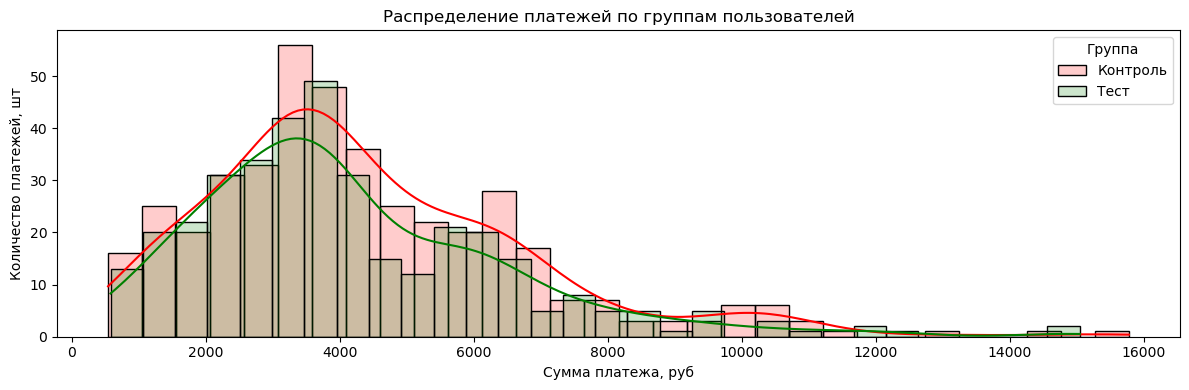

Т-тест Стюдента для средних платежей:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.03686899928098654, а значение t-критерия равно 2.0892718943323443
Значения двух выборок имеют статистически значимые различия


Т-тест Стюдента для средних значений конверсии в платеж:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.10498894497258296, а значение t-критерия равно 1.6222173039489063
Статистически значимых различий между двумя выборками не обнаружено


Тест Манна-Уитни для средних платежей:
Согласно проведенному непараметрическому тесту Манна-Уитни для средних значений двух независимых выборок
p-value равен 0.03323940159324537, а значение U-статистики для первой выборки равно 245743.0
Значения двух выборок имеют статистически значимые различия


Сочи 



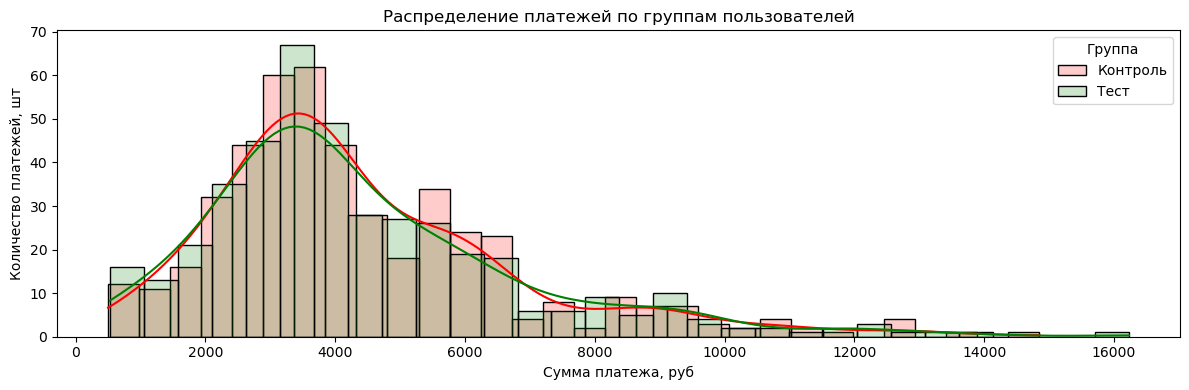

Т-тест Стюдента для средних платежей:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.12297605685687812, а значение t-критерия равно 1.5432162776667724
Статистически значимых различий между двумя выборками не обнаружено


Т-тест Стюдента для средних значений конверсии в платеж:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.047319885252583245, а значение t-критерия равно 1.9849560691617736
Значения двух выборок имеют статистически значимые различия


Тест Манна-Уитни для средних платежей:
Согласно проведенному непараметрическому тесту Манна-Уитни для средних значений двух независимых выборок
p-value равен 0.05698257474271896, а значение U-статистики для первой выборки равно 337587.5
Статистически значимых различий между двумя выборками не обнаружено


Владимир 



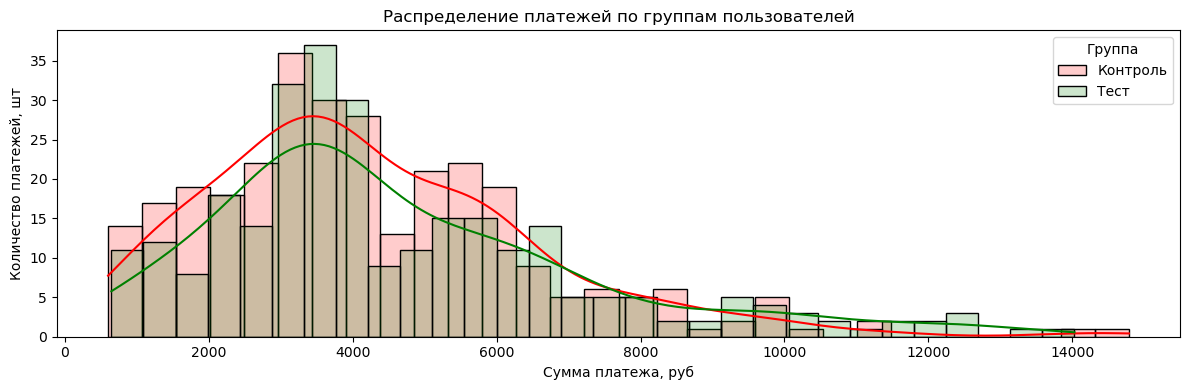

Т-тест Стюдента для средних платежей:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.010095112170351712, а значение t-критерия равно -2.5769554932923184
Значения двух выборок имеют статистически значимые различия


Т-тест Стюдента для средних значений конверсии в платеж:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.08481593543159477, а значение t-критерия равно -1.724937016780416
Статистически значимых различий между двумя выборками не обнаружено


Тест Манна-Уитни для средних платежей:
Согласно проведенному непараметрическому тесту Манна-Уитни для средних значений двух независимых выборок
p-value равен 0.03166761411886426, а значение U-статистики для первой выборки равно 143847.0
Значения двух выборок имеют статистически значимые различия


Самара 



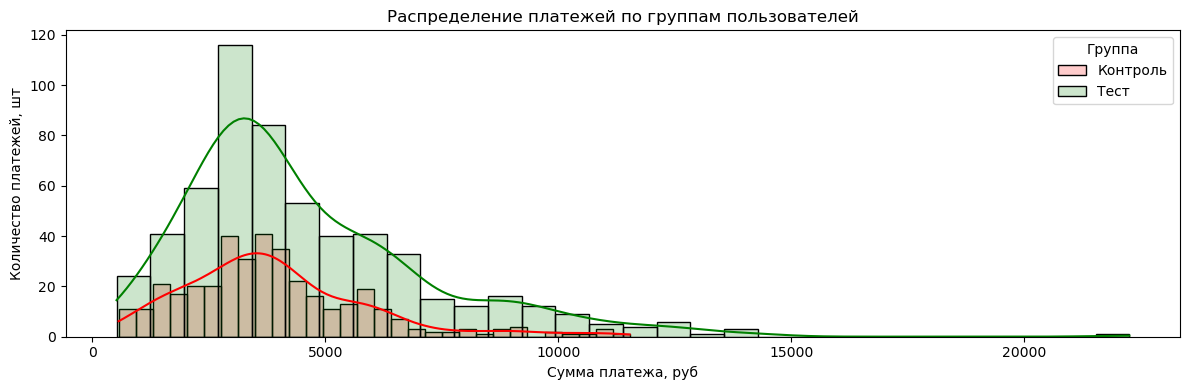

Т-тест Стюдента для средних платежей:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 1.1014020778472052e-29, а значение t-критерия равно -11.54083248253458
Значения двух выборок имеют статистически значимые различия


Т-тест Стюдента для средних значений конверсии в платеж:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 3.981449742682522e-31, а значение t-критерия равно -11.846151689470245
Значения двух выборок имеют статистически значимые различия


Тест Манна-Уитни для средних платежей:
Согласно проведенному непараметрическому тесту Манна-Уитни для средних значений двух независимых выборок
p-value равен 4.325201867794148e-30, а значение U-статистики для первой выборки равно 233516.5
Значения двух выборок имеют статистически значимые различия


Краснодар 



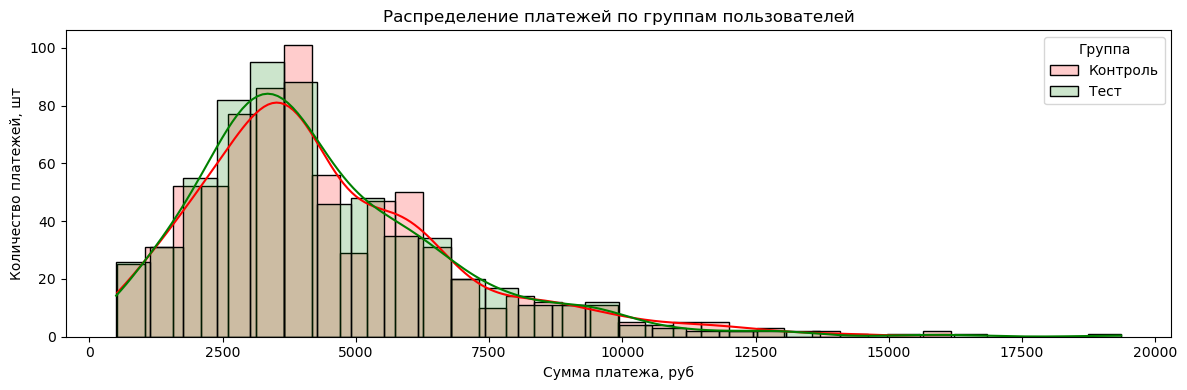

Т-тест Стюдента для средних платежей:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.085800112916198, а значение t-критерия равно 1.718766529966594
Статистически значимых различий между двумя выборками не обнаружено


Т-тест Стюдента для средних значений конверсии в платеж:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.06038527567849974, а значение t-критерия равно 1.8789539353324407
Статистически значимых различий между двумя выборками не обнаружено


Тест Манна-Уитни для средних платежей:
Согласно проведенному непараметрическому тесту Манна-Уитни для средних значений двух независимых выборок
p-value равен 0.05938101983441801, а значение U-статистики для первой выборки равно 609837.0
Статистически значимых различий между двумя выборками не обнаружено


Сахалинск 



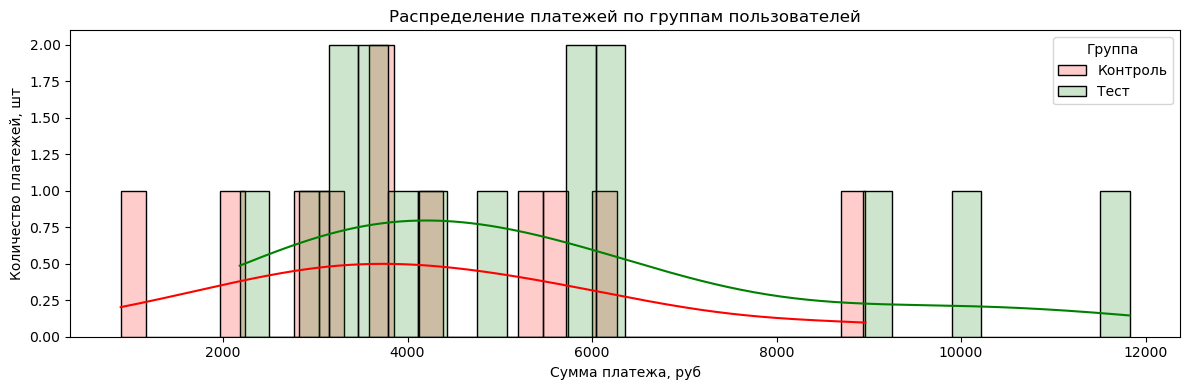

Т-тест Стюдента для средних платежей:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.105809212549273, а значение t-критерия равно -1.6270604929283117
Статистически значимых различий между двумя выборками не обнаружено


Т-тест Стюдента для средних значений конверсии в платеж:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.24367247406936435, а значение t-критерия равно -1.1704284638604743
Статистически значимых различий между двумя выборками не обнаружено


Тест Манна-Уитни для средних платежей:
Согласно проведенному непараметрическому тесту Манна-Уитни для средних значений двух независимых выборок
p-value равен 0.19868569514015844, а значение U-статистики для первой выборки равно 2690.5
Статистически значимых различий между двумя выборками не обнаружено


Дмитров 



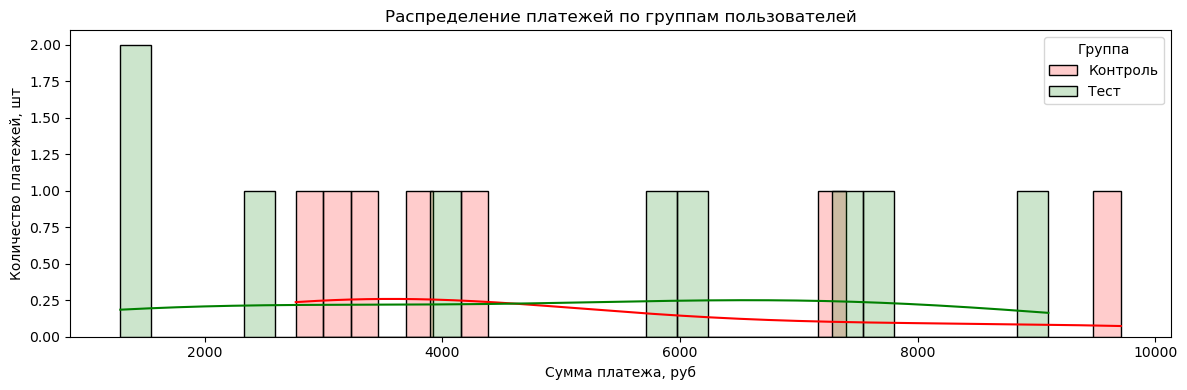

Т-тест Стюдента для средних платежей:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.7410763125801646, а значение t-критерия равно -0.3310524347645207
Статистически значимых различий между двумя выборками не обнаружено


Т-тест Стюдента для средних значений конверсии в платеж:
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.7429421277261776, а значение t-критерия равно -0.3285782051097397
Статистически значимых различий между двумя выборками не обнаружено


Тест Манна-Уитни для средних платежей:
Согласно проведенному непараметрическому тесту Манна-Уитни для средних значений двух независимых выборок
p-value равен 0.7422551789442879, а значение U-статистики для первой выборки равно 2722.0
Статистически значимых различий между двумя выборками не обнаружено




In [90]:
city_list = []

for i in df_final['city'].unique():
    if (i != 'Москва') and (i != 'Санкт-Петербург'):
        city_list.append(i)

for item in city_list:
    print(item, '\n')


    df_final_city = df_final[df_final['city'] == item]

    data_test_city = df_final_city[(df_final_city['nflag_test'] == 1) & (df_final_city['all_payments'] > 0)]
    data_control_city = df_final_city[(df_final_city['nflag_test'] == 0) & (df_final_city['all_payments'] > 0)]

    fig, ax = plt.subplots(figsize = (12, 4))

    sns.histplot(data = data_control_city, x = 'all_payments', bins=30, color='red', alpha = 0.2, label = 'Контроль', kde = True)
    sns.histplot(data = data_test_city, x = 'all_payments', bins=30, color='green', alpha = 0.2, label = 'Тест', kde = True)

    ax.set_title('Распределение платежей по группам пользователей')
    ax.set_xlabel('Сумма платежа, руб')
    ax.set_ylabel('Количество платежей, шт')
    ax.legend(title = 'Группа')
    plt.tight_layout()
    plt.show()

    
    print('Т-тест Стюдента для средних платежей:')
    test_calc(
        df_final[(df_final['nflag_test'] == 0) & (df_final['city'] == item)]['all_payments'],
        df_final[(df_final['nflag_test'] == 1) & (df_final['city'] == item)]['all_payments']
    )
    print('\n')
    print('Т-тест Стюдента для средних значений конверсии в платеж:')
    test_calc(
        df_final[(df_final['nflag_test'] == 0) & (df_final['city'] == item)]['payment_flag'], 
        df_final[(df_final['nflag_test'] == 1) & (df_final['city'] == item)]['payment_flag']
    )
    print('\n')
    print('Тест Манна-Уитни для средних платежей:')
    mann_whitney_func(
        df_final[(df_final['nflag_test'] == 0) & (df_final['city'] == item)]['all_payments'], 
        df_final[(df_final['nflag_test'] == 1) & (df_final['city'] == item)]['all_payments']
    )
    print('\n')
    

Вывод: В Тюмени были обнаружены статистически значимые различия в Т-тесте по конверсии платеж, а также в тесте Манна-Уитни для средних платежей. В Волгограде т-тест и тест Манна-Уитни показали статистически значимую разницу для средних платежей. В Сочи стат.значимые различия обнаружены для т-теста на конверсию в платеж. Во Владимире стат.значимые различия обнаружены в т-тесте и тесте Манна-Уитни на средние платежи. Самара является единственным городом, где обнаружены стат.значимые различия во всех тестах на средний платеж и конверсию в платеж.

# 7. Отчет по A/B-тесту

7.1 Создайте пустой датафрейм. Запустите цикл по всем городам и торговым точкам.
7.2 Заполните для каждой торговой точки все поля, указанные в требовании к таблице.
7.3 Не забудьте задать один из трех лейблов, в зависимости от результата теста в данной торговой точке.


In [91]:
df_export = pd.DataFrame()

for i in df_final['city'].unique(): #для каждого города
    df_loc = df_final[df_final['city'] == i]
    for j in df_loc['id_trading_point'].unique(): #для каждой ТТ в городе
        tt_df = df_loc[df_loc['id_trading_point'] == j]

        count_test = len(tt_df[tt_df['nflag_test'] == 1])
        count_control = len(tt_df[tt_df['nflag_test'] == 0])
        count_all = len(tt_df)
        percent_count = count_all / len(df_final)
        avg_payment_test = tt_df[tt_df['nflag_test'] == 1]['all_payments'].mean()
        avg_payment_control = tt_df[tt_df['nflag_test'] == 0]['all_payments'].mean()
        diff = avg_payment_test - avg_payment_control 
        sigma_test = tt_df[tt_df['nflag_test'] == 1]['all_payments'].std()
        sigma_control = tt_df[tt_df['nflag_test'] == 0]['all_payments'].std()
        ttest, pvalue_ttest = test_calc(tt_df[tt_df['nflag_test'] == 1]['all_payments'], tt_df[tt_df['nflag_test'] == 0]['all_payments'])
        

        df_export = df_export._append({
			'city':i,
            'id_trading_point': j,
            'count_test': count_test,
            'count_control': count_control,
            'percent_count': percent_count,
            'avg_payment_test': avg_payment_test,
            'avg_payment_control': avg_payment_control,
            'diff': diff,
            'sigma_test': sigma_test,
            'sigma_control': sigma_control,
            'ttest': ttest,
            'pvalue_ttest': pvalue_ttest
              }, ignore_index=True)

df_export['labels'] = np.where((df_export['diff'] > 0) & (df_export['pvalue_ttest'] < 0.05), 'Positive',
                      np.where ((df_export['diff'] < 0) & (df_export['pvalue_ttest'] < 0.05), 'Negative', 'Neutral'))

df_export.head(100)

Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.6287709476405416, а значение t-критерия равно -0.4835853855099397
Статистически значимых различий между двумя выборками не обнаружено
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.06901056074583502, а значение t-критерия равно 1.8202681201948652
Статистически значимых различий между двумя выборками не обнаружено
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.2483082639044714, а значение t-критерия равно 1.155072918440385
Статистически значимых различий между двумя выборками не обнаружено
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.3808017001028424, а значение t-критерия равно -0.8767403719314057
Статистически значимых различий между двумя выборками не обнаружено
Согласно проведенному T-тесту для средних значений двух независимых выборок
p-value равен 0.326412

,city,id_trading_point,count_test,count_control,percent_count,avg_payment_test,avg_payment_control,diff,sigma_test,sigma_control,ttest,pvalue_ttest,labels
0,Красноярск,212,593,575,0.025773,2144.317032,2222.052174,-77.735142,2708.588724,2785.116250,-0.483585,6.287709e-01,Neutral
1,Красноярск,278,535,489,0.022596,2499.345794,2185.214724,314.131070,2915.995329,2574.915597,1.820268,6.901056e-02,Neutral
2,Красноярск,202,551,565,0.024626,2927.341198,2730.378761,196.962437,2956.686241,2737.885785,1.155073,2.483083e-01,Neutral
3,Красноярск,444,650,562,0.026744,2404.106154,2545.734875,-141.628722,2810.828487,2797.138764,-0.876740,3.808017e-01,Neutral
4,Красноярск,277,708,709,0.031268,2285.750000,2431.365303,-145.615303,2712.677878,2868.587569,-0.981705,3.264128e-01,Neutral
5,Мурманск,54,633,640,0.028090,1702.714060,1688.512500,14.201560,2565.132440,2628.012490,0.097556,9.223005e-01,Neutral
6,Мурманск,55,422,425,0.018690,2109.106635,2111.272941,-2.166306,2790.993385,2804.223188,-0.011268,9.910125e-01,Neutral
7,Казань,991,270,294,0.012445,3249.281481,2452.986395,796.295087,4719.592601,3633.935858,2.255258,2.450100e-02,Positive
8,Казань,699,482,494,0.021537,2422.286307,2574.352227,-152.065920,3906.817897,4082.851356,-0.594254,5.524804e-01,Neutral
9,Казань,477,382,386,0.016947,2259.623037,2496.987047,-237.364010,3482.846094,3881.994719,-0.891593,3.728909e-01,Neutral


7.4 Выгрузите полученные результаты в Excel. Разнесите результаты по трем разным листам в зависимости от лейбла.

In [92]:
writer = pd.ExcelWriter("Diplom.xlsx", engine="xlsxwriter")

df_export[df_export['labels']=='Positive'].to_excel(writer, sheet_name="Sheet1")
df_export[df_export['labels']=='Negative'].to_excel(writer, sheet_name="Sheet2")
df_export[df_export['labels']=='Neutral'].to_excel(writer, sheet_name="Sheet3")

writer.close()